# 分组处理

分组聚合是数据分析中很常用的操作，例如对销售额按地区汇总、日志按小时计数、实验数据按组求均值，基本做法相同：先按某一列或多个列的值把行分成若干组，再对每组算出一个值。

Polars 把这项工作拆成两步来完成：`group_by()` 负责分组，`agg()` 负责计算。这样拆开的好处是，两步之间可以放任意表达式，因此“每组取前三条”“每组同时算最大值和均值”这类需求，都只需要换一下 `agg()` 里的表达式，不必再另写函数。这一章从这个组合讲起，接着是用聚合结果反过来筛选分组的 `having()`、把组内结果放回原来那些行的 `over()`，最后是沿时间轴和行数开窗的 `group_by_dynamic()` 与 `rolling()`。
- `group_by`：按列的值分组
- `agg`：每组算出一个结果
- `having`：用聚合结果反过来筛组
- `over`：把每组的计算结果放回原来的行
- `group_by_dynamic` / `rolling`：按时间轴或行号的窗口聚合

这几个方法共用同一个“分组 → 聚合”的框架，区别只在于结果如何回到行上：`agg()` 把每组压缩成 1 行，`over()` 把每组的 1 个值广播给组内所有的行。

In [1]:
import polars as pl
from helper.jupyter import row

## group_by

`DataFrame.group_by()` 返回一个分组对象 `GroupBy`。此时还没有真正计算，它只记录“按哪些列分组”，真正的计算要等 `agg()` 或 `mean()` 这类方法被调用才会运行。

`GroupBy` 对象本身很轻，只保存分组键和原表的引用；可以对同一个对象连续调用不同的聚合方法，每次都会重新执行一次分组。需要同时算多个统计量时，应把表达式放进同一次 `agg()`，避免重复分组。

有一个细节需要注意：为了提高运算速度，默认情况下不保证分组的顺序。Polars 会并行处理各分组，因此结果的顺序与数据的顺序无关。如果需要按数据中出现的顺序遍历结果，应显式指定 `maintain_order=True`，代价是运算速度略有下降。

In [2]:
df = pl.DataFrame(
    dict(
        g=['A', 'B', 'C', 'A', 'B', 'B'], 
        x=[1, 2, 3, 4, 5, 6])
)
g = df.group_by('g', maintain_order=True)
type(g)

polars.dataframe.group_by.GroupBy

### 用 agg 聚合

把表达式传给 `GroupBy.agg()`，Polars 就按组计算，并把每个组压缩成 1 行：表达式在每个组内部求值一次，结果放进对应的那一行。

常用的聚合还有 `GroupBy` 自身的方法形式，例如 `.mean()`、`.first()`、`.sum()`。这些方法等价于在 `agg()` 里写同样的表达式，结果完全相同，只是写法更短。一次要计算多个统计量时，用 `agg()` 更方便，因为一条调用就能返回多列，而 `.mean()` 这类调用只能给出一列。

In [3]:
row(
    g.mean(), 
    g.agg(pl.all().mean()),
    g.first(),
    g.agg(pl.all().first())
)

g,x
str,f64
"""A""",2.5
"""B""",4.333333
"""C""",3.0
g,x
str,f64
"""A""",2.5
"""B""",4.333333
"""C""",3.0
g,x


如果 `agg()` 里的表达式返回多个值，例如 `head(2)` 返回 2 行，结果列就会变成列表。原因是 `agg()` 给每个组只留 1 行，而表达式给出的值不止一个，多出来的值只能放进列表。

如果想得到 `GroupBy.head()` 那种“组还是多行”的形状，用 `explode()` 把列表纵向展开即可，展开后的行数与 `GroupBy.head()` 一致。两个方法的区别只在结果的行数是否被压缩成 1 行。

In [4]:
row(
    g.head(2), 
    g.agg(pl.all().head(2)), 
    g.agg(pl.all().head(2)).explode('x')
)

g,x
str,i64
"""A""",1
"""A""",4
"""B""",2
"""B""",5
"""C""",3
g,x
str,list[i64]
"""A""","[1, 4]"
"""B""","[2, 5]"


`agg()` 里也可以调用自定义函数，用 `map_batches()` 把整组的数据交给它处理。这时函数被调用的次数等于组的个数，而不是行的个数，分组一多，这部分开销会明显上升。具体写法和 `is_elementwise` 的影响，见[在 GroupBy.agg() 里使用 map_batches()](map_batches_in_agg)。

### 用 having 筛组

聚合之后，常常需要“只保留满足条件的组”，例如订单数超过 10 的客户、平均分低于 60 的班级。这类筛选不能用 `filter()` 代替。因为这里判断的是每个组的统计量，而 `filter()` 只能看到每一行自己的值，无法判断某一行属于哪个组。

在 SQL 里，这个功能由 `HAVING` 子句提供，Polars 里对应的方法是 `GroupBy.having()`。它的参数是一个含聚合表达式的条件，写法和 `filter()` 相同，返回值仍然是 `GroupBy` 对象，因此后面可以接着写 `agg()` 或 `mean()`。下面的例子先统计每组的件数，把只有 1 件的 `C` 去掉，再计算平均值。

In [5]:
g.having(pl.col('g').count() > 1).mean()

g,x
str,f64
"""A""",2.5
"""B""",4.333333


`having()` 与 `filter()` 判断的对象不同：`having()` 看每组统计量，`filter()` 看当前行的值。因此能写进 `having()` 的条件一定含聚合表达式，能写进 `filter()` 的条件通常不含。

| 方法       | 筛选对象 | 典型条件               |
|------------|----------|------------------------|
| `filter()` | 行       | `pl.col("x") > 3`      |
| `having()` | 组       | `pl.col("x").mean() > 3` |

(over)=
## over

`.over()` 用在表达式里，作用是把按组计算出来的结果分发回原来的行，行数保持不变。

`group_by().agg()` 的结果是一组一行，而 `.over()` 是一组一个值，再把这个值广播到组内所有的行上。如果要用组内的统计量参与逐行计算，例如减去组均值、把本行与组内的最大值比较，都需要用 `over()`。

不用 `.over()` 而先聚合再连接，也能得到同样的结果，只是步骤会多不少：先按组把值算出来，得到一张每个组只有一行的小表，再按组键把这张小表连接回原表。连接时两边的组键都必须唯一，否则一次连接会匹配出多行，行数就被放大了。

与 `join` 相比，`.over()` 的优势是不需要把中间结果物化成一张小表，也不会因为组键重复而放大行数；代价是它只能把结果放回原表，不能像 `join` 那样引入新的键。

In [6]:
df.with_columns(
    pl.col('x').mean()
    .over('g').alias('x_mean')
)

g,x,x_mean
str,i64,f64
"""A""",1,2.5
"""B""",2,4.333333
"""C""",3,3.0
"""A""",4,2.5
"""B""",5,4.333333
"""B""",6,4.333333


下面的代码按 `g` 分组算出 `x` 的平均值，再用 `x` 减去这个平均值，结果放进新列 `x_sub_mean`。

这就是常说的“组内去均值”。每组的计算结果会回到对应的行上，行数保持不变。因此这一列可以接着参与排序、过滤，或者作为后面窗口计算的输入。

In [7]:
df.with_columns(
    (pl.col('x') - pl.col('x').mean())
    .over('g')
    .alias('x_sub_mean')
)

g,x,x_sub_mean
str,i64,f64
"""A""",1,-1.5
"""B""",2,-2.333333
"""C""",3,0.0
"""A""",4,1.5
"""B""",5,0.666667
"""B""",6,1.666667


`.over()` 对结果的长度有要求：每个组算出来的长度要么是 1，要么正好等于该组的行数。两者都不满足时，例如 `.head(2)` 返回 2 行而组里有 3 行，直接写就会报错。原因是 Polars 必须把结果按行放回去，长度对不上，就无法确定多出来的值该放到哪一行。

指定 `mapping_strategy='join'` 可以绕开这个限制，做法是把结果整体作为列表放进该组的那一行。下面的例子把每组前 2 条收成一个列表，放进新列。

In [8]:
df.with_columns(
    pl.col('x').head(2)
    .over('g', mapping_strategy='join')
    .alias('x_head')
)

g,x,x_head
str,i64,list[i64]
"""A""",1,"[1, 4]"
"""B""",2,"[2, 5]"
"""C""",3,[3]
"""A""",4,"[1, 4]"
"""B""",5,"[2, 5]"
"""B""",6,"[2, 5]"


下面的代码按 `g` 分组取 `x` 的最小值和最大值，把这两个值作为一个列表放进新列。

`append()` 在表达式里把两个标量拼成一个长度 2 的列表，正好符合 `mapping_strategy='join'` 需要的形状：一个组对应一个值，而这个值是长度为 2 的列表。

In [9]:
df.with_columns(
    pl.col('x').min().append(pl.col('x').max())
    .over('g', mapping_strategy='join')
    .alias('x_min_max')
)

g,x,x_min_max
str,i64,list[i64]
"""A""",1,"[1, 4]"
"""B""",2,"[2, 6]"
"""C""",3,"[3, 3]"
"""A""",4,"[1, 4]"
"""B""",5,"[2, 6]"
"""B""",6,"[2, 6]"


`mapping_strategy='explode'` 把每组的结果纵向展开，效果与先 `agg()` 再 `explode()` 相同，但省掉了两步之间的物化。

它适合“每个组要展开成若干行、列结构又不想改变”的场景。两个策略的差别只在结果的行数：`join` 把列表放进一行，`explode` 把列表展开成多行。

In [10]:
df.select(
    pl.col('g', 'x').head(2)
    .over('g', mapping_strategy='explode')
)

g,x
str,i64
"""A""",1
"""A""",4
"""B""",2
"""B""",5
"""C""",3


`filter()` 里也能用带 `.over()` 的表达式，条件是“这一行与它所在组的统计量相比如何”。

下面的代码按 `g` 分组，保留 `x` 不小于该组平均值的行。这类“保留组内高于均值”的筛选若不用窗口表达式，需要先算出每组的均值、单独存成一张每个组只有一行的小表，再按组键把这张小表连接回原表，最后才能筛选。这几步写成一条 `.over()` 表达式就能完成。

In [11]:
df.filter(
    (pl.col('x') >= pl.col('x').mean())
    .over('g')
)

g,x
str,i64
"""C""",3
"""A""",4
"""B""",5
"""B""",6


## group_by_dynamic

`group_by_dynamic(index)` 按 `index` 列的值做时间窗口分组，是时序降采样的主力函数。它与 `group_by()` 的根本区别在于分组键的来源：键不是数据里现成的列，而是把时间轴切成等长的格子，一个格子算作一组。

第一组的起点 `start` 由 `start_by`、`every`、`offset` 和 `index` 的第一个值 `value` 共同决定。`start_by='window'` 是默认值，此时按下式计算：

```
start = value - (value - offset) % every
```

这个式子的做法是把时间轴按 `every` 切成固定的格子，再让第一个值落进它所属的那一格，取这一格的起点作为第一组的起点。之所以要这样对齐，是为了让窗口边界落在固定的时间刻度上，而不是落在第一个数据点上。这样不同时间段分别算出来的组，位置才可以互相比较。

`start_by='datapoint'` 的做法不同：`start` 直接取第一个数据点，格子从数据开始处向外铺开，`offset` 只影响后面各组的位置。

起点确定之后，各组范围依次如下。`period` 的默认值与 `every` 相同。

```
[start, start + period)
[start + every, start + every + period)
...
[start + i * every, start + i * every + period)
```

每组的起始值就是这一组的键。指定 `include_boundaries=True` 会多出 `_lower_boundary` 和 `_upper_boundary` 两列，给出每组的开始与结束，前者包含、后者不包含。排查“这一行为什么没有进组”时，先看这两列，比逐行读代码快得多。

下面的例子把 `index` 的值每 3 个单位并成一组聚合。

In [12]:
index = [1, 2, 4, 5, 6, 8, 9, 10, 11]
# 先把 index 升序排好（set_sorted 声明已排序）
df = pl.DataFrame(dict(index=index, value=list(range(len(index))))).set_sorted("index")

g = df.group_by_dynamic("index", every="3i", offset="0i", include_boundaries=True)
row(df, g.agg(pl.col("index").alias("index_in_group")))

index,value
i64,i64
1,0
2,1
4,2
5,3
6,4
8,5
9,6
10,7
11,8


为了直观确认分组结果，本书提供了 `plot_group_by_dynamic()`，把组的边界画在时间轴上：蓝线是 `index` 的值，红线是每组的键，绿块是每组的取值范围。从图上可以直接看出哪些点被并到了一起。

[[1, 2], [4, 5], [6, 8], [9, 10, 11]]


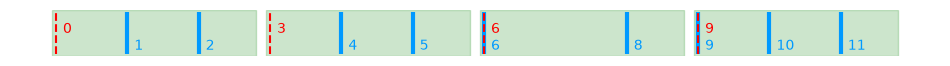

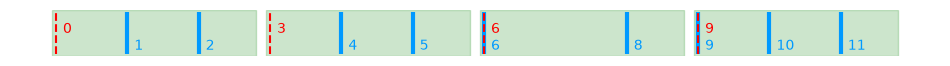

In [13]:
from helper import utils
from helper.utils import plot_group_by_dynamic
from matplotlib import pyplot as plt
plt.ioff()
plot_group_by_dynamic(index, every='3i', offset='0i')

下面输出三张图，分别对应不同的 `offset`。可以看到格子整体往后挪，每张图里各行的归属也跟着改变。

[[1, 2], [4, 5, 6], [8, 9], [10, 11]]


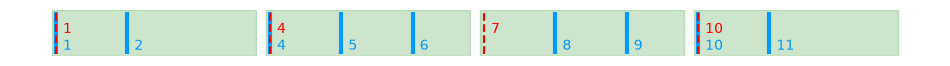

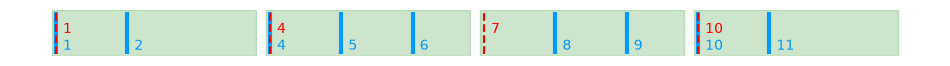

In [14]:
plot_group_by_dynamic(index, every='3i', offset='1i')

[[1], [2, 4], [5, 6], [8, 9, 10], [11]]


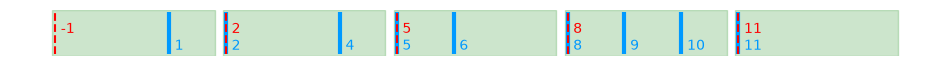

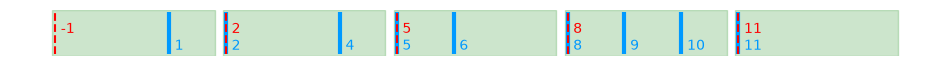

In [15]:
plot_group_by_dynamic(index, every='3i', offset='2i')

[[1], [2, 4], [5, 6], [8, 9, 10], [11]]


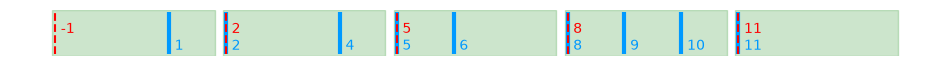

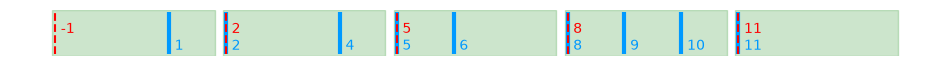

In [16]:
plot_group_by_dynamic(index, every='3i', offset='-1i')

`start_by='datapoint'` 时，第一组的起点固定为 `index` 的第一个值，`offset` 不再影响起点。也就是说，数据从哪里开始，格子就从哪里开始排，不会为了对齐时间刻度而在前面留出空白。

[[1, 2], [4, 5, 6], [8, 9], [10, 11]]


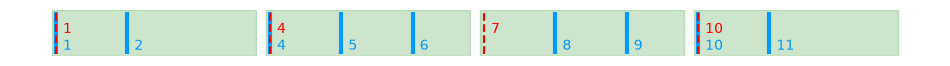

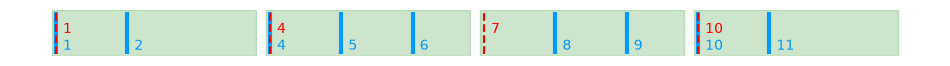

In [17]:
plot_group_by_dynamic(index, every='3i', start_by='datapoint')

`period` 的默认值与 `every` 相同，所以组与组之间不重叠，每一条记录只落进一个组。

如果 `period` 比 `every` 大，窗口就会重叠，同一个 `index` 会落进多个组，适合做滑动平均这类统计。代价是同一条记录被计算多次，结果的行数比原数据多。

[[1, 2, 4], [4, 5, 6], [6, 8, 9, 10], [9, 10, 11]]


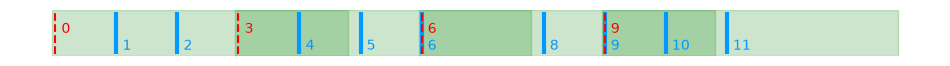

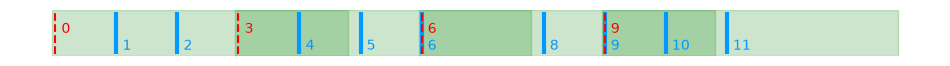

In [18]:
plot_group_by_dynamic(index, every='3i', period='5i')

下面的代码让窗口每次移动 1 个单位、长度固定为 3 个单位。每一行都会开启一个新窗口，相邻窗口之间重叠 2 个单位。

In [19]:
g = df.group_by_dynamic('index', every='1i', period='3i', include_boundaries=True)
row(df, g.agg(pl.col("index").alias('index_in_group')))

index,value
i64,i64
1,0
2,1
4,2
5,3
6,4
8,5
9,6
10,7
11,8


这里用整数列演示，实际使用中多为时间序列。`every`、`period`、`offset` 支持下面这些单位。
- `1ns` 纳秒、`1us` 微秒、`1ms` 毫秒
- `1s` 秒、`1m` 分、`1h` 小时
- `1d` 天、`1w` 周、`1mo` 月、`1q` 季度、`1y` 年

## rolling

`rolling(index)` 也按 `index` 列的值开窗，但它既不做分组，也不降采样：它为每一行给出一个“往前或往后看一段”的窗口，行数保持不变。

`period` 和 `offset` 决定窗口的位置。`offset` 的默认值是 `-period`，也就是默认往过去看。窗口是左开右闭的：

```
(index[0] + offset, index[0] + offset + period]
...
(index[i] + offset, index[i] + offset + period]
```

式子左端的小括号表示不含，右端的中括号表示含。边界上的取舍因此很关键：恰好落在右端的记录会被算进来，落在左端的不会。

下面的例子用包含前 2 个点的 3 点窗口聚合。

In [20]:
g = df.rolling('index', period='3i')
g.agg(pl.col("value"))

index,value
i64,list[i64]
1,[0]
2,"[0, 1]"
4,"[1, 2]"
5,"[2, 3]"
6,"[2, 3, 4]"
8,"[4, 5]"
9,"[5, 6]"
10,"[5, 6, 7]"
11,"[6, 7, 8]"


下面的代码按 `index` 造窗口，每个窗口包含该点之后的 2 个点，共 3 个点。把 `offset` 设为正值，窗口就朝未来看。

In [21]:
g = df.rolling('index', period='3i', offset='-1i')
g.agg(pl.col("value"))

index,value
i64,list[i64]
1,"[0, 1]"
2,"[1, 2]"
4,"[2, 3, 4]"
5,"[3, 4]"
6,"[4, 5]"
8,"[5, 6, 7]"
9,"[6, 7, 8]"
10,"[7, 8]"
11,[8]


要按固定行数开窗，就用 `int_range()` 生成一列行号，再把这列交给 `rolling()`。

下面的代码用“前 2 行加本行”共 3 行做窗口，算 `A` 的最大值和 `B` 的最小值。窗口按行数走，不按值走，因此 `index` 的间隔是否均匀都不影响结果。

In [22]:
df = pl.DataFrame(
    dict(
        A=[5, 3, 8, 9, 10, 1, 2, 4],
        B=[10, 20, 10, 2, 3, 5, 0, 7]
    )
)

(
    df
    .rolling(
        pl.int_range(0, pl.len()).alias('index'), 
        period='3i', 
        offset='-2i'
    )
    .agg(
        pl.col.A,
        pl.col.B,
        pl.col.A.max().alias('A_max'),
        pl.col.B.min().alias('B_min'),
    )
)

index,A,B,A_max,B_min
i64,list[i64],list[i64],i64,i64
0,"[5, 3]","[10, 20]",5,10
1,"[5, 3, 8]","[10, 20, 10]",8,10
2,"[3, 8, 9]","[20, 10, 2]",9,2
3,"[8, 9, 10]","[10, 2, 3]",10,2
4,"[9, 10, 1]","[2, 3, 5]",10,2
5,"[10, 1, 2]","[3, 5, 0]",10,0
6,"[1, 2, 4]","[5, 0, 7]",4,0
7,"[2, 4]","[0, 7]",4,0


也有 `Expr.rolling()`，参数与 `DataFrame.rolling()` 相同，但写在列上更灵活：它接在表达式后面，窗口作用在整条表达式的结果上，不必先把结果物化成一列再开窗。

In [23]:
df.with_row_index().select(
    pl.col('A').rolling('index', period='3i', offset='-2i'),
    pl.col('A').max().rolling('index', period='3i', offset='-2i').alias('A_max')
)

A,A_max
list[i64],i64
"[5, 3]",5
"[5, 3, 8]",8
"[3, 8, 9]",9
"[8, 9, 10]",10
"[9, 10, 1]",10
"[10, 1, 2]",10
"[1, 2, 4]",4
"[2, 4]",4


`.rolling()` 作用于它前面整条表达式，而不只是紧邻的那个函数。两种写法的差别全在这里。
1. `pl.col('A').diff().max().rolling(...)`，也就是 ❶：先把 `A` 切进窗口，再在每个窗口内部计算 `.diff().max()`，得到“窗口内的最大差分”。
2. 先算差分再开窗，也就是 ❷：先把 `dA = pl.col('A').diff()` 做成新列，再对它套 `.max().rolling(...)`，得到“差分序列的窗口最大值”。

两者结果不同，写代码之前先确定需要哪一种。不确定时，可以把两种写法并排放进同一张表里对比。

In [24]:
df1 = df.select('A').with_row_index().with_columns(
    pl.col('A').rolling('index', period='3i'),
    pl.col('A').diff().rolling('index', period='3i').alias('dA_rolling'),
    pl.col('A').diff().max().rolling('index', period='3i').alias('dA_max_rolling') #❶
)

df2 = df.select('A').with_row_index().with_columns(
    pl.col('A').diff().alias('dA') #❷
).with_columns(
    pl.col('dA').rolling('index', period='3i').alias('dA_rolling'),
    pl.col('dA').max().rolling('index', period='3i').alias('dA_max_rolling') #❷
)

row(df1, df2)

shape: (8, 4) index A dA_rolling dA_max_rolling u32 list[i64] list[i64] i64 0 [5] [null] null 1 [5, 3] [null, -2] -2 2 [5, 3, 8] [null, -2, 5] 5 3 [3, 8, 9] [null, 5, 1] 5 4 [8, 9, 10] [null, 1, 1] 1 5 [9, 10, 1] [null, 1, -9] 1 6 [10, 1, 2] [null, -9, 1] 1 7 [1, 2, 4] [null, 1, 2] 2 
 shape: (8, 5) index A dA dA_rolling dA_max_rolling u32 i64 i64 list[i64] i64 0 5 null [null] null 1 3 -2 [null, -2] -2 2 8 5 [null, -2, 5] 5 3 9 1 [-2, 5, 1] 5 4 10 1 [5, 1, 1] 5 5 1 -9 [1, 1, -9] 1 6 2 1 [1, -9, 1] 1 7 4 2 [-9, 1, 2] 2

## CookBook

### 按值的变化分组聚合

下面的代码在 `g` 的值每次变化时换一组，取每组的第一个 `g` 和 `v`。

`rle_id()` 给连续相同的值同一个编号，值一旦变化就分配新编号。这正是“连续重复值分组”的关键：普通 `group_by()` 会把所有相同的值归成一组，即使它们中间隔着别的值。而这里要的是被别的值隔开的若干段，`rle_id()` 把段变成了可以直接用来分组的键。

In [25]:
df = pl.DataFrame(
    {
        "g": [1, 1, 2, 2, 2, 1, 1, 0],
        "v": list(range(8))
    }
)

df.group_by(
    pl.col('g').rle_id().alias('group_id')
).agg(
    pl.col('g').first(),
    pl.col('v')
)

group_id,g,v
u32,i64,list[i64]
0,1,"[0, 1]"
1,2,"[2, 3, 4]"
2,1,"[5, 6]"
3,0,[7]


### 按组编号

给 `c1` 和 `c2` 的值组合编号，从 0 开始，出现新组合就加 1。这实际上是把复合键映射成整数 ID。

Polars 2.0 删除了 `agg_groups()`，所以下面给出三种实现。三者的区别在于编号从哪里来：先分组再展开、先做一张每个组合只有一行的表再连回原表、直接借用类别型的内部编号。

In [26]:
df = pl.DataFrame(
    {
        "c1": ["b", "a", "a", "b", "c", "a", "b"],
        "c2": [2, 1, 1, 1, 1, 1, 1],
    }
)

#### 用 group_by 计算

1. `group_by("c1", "c2", maintain_order=True)`：按两列的组合分组，并保持首次出现的顺序。这一步决定了编号的先后，去掉 `maintain_order=True` 编号就会随分组完成的先后变化。
2. `agg(pl.col("row_index"))`：把行号按组收成列表。Polars 2.0 删除了 `agg_groups()`，所以先用 `with_row_index()` 造一列行号，再对这列做聚合。
3. `explode("row_index")`：把列表展开成行，每个组合的编号就复制到了组内每一行。
4. `sort("row_index")`：恢复原来的行序。
5. `drop("row_index")`：去掉临时列。

In [27]:
(
    df.with_row_index("row_index")
    .group_by("c1", "c2", maintain_order=True)
    .agg(pl.col("row_index"))
    .explode("row_index")
    .sort("row_index")
    .drop("row_index")
)

c1,c2
str,i64
"""b""",2
"""a""",1
"""a""",1
"""b""",1
"""c""",1
"""a""",1
"""b""",1


#### 用 join 计算

用 `join` 也能得到同样的结果，思路是“先给唯一组合编好号，再按组合连回原表”。
1. `df.select('c1', 'c2')`：只取两列键。
2. `unique(maintain_order=True)`：取唯一的组合，保持出现顺序。
3. `with_row_index()`：加行号，这个行号就是编号。
4. `df.join(..., on=["c1", "c2"])`：把原表与带编号的唯一组合按两列连起来。

与第一种相比，这里多做一次连接：编号要先做成一张每个组合只有一行的表，再按 `c1`、`c2` 连回原表。好处是编号独立成一列，原表的行序不必再保证。

In [28]:
df.join(
    df.select('c1', 'c2')
    .unique(maintain_order=True)
    .with_row_index(),
    on=["c1", "c2"]
)

c1,c2,index
str,i64,u32
"""b""",2,0
"""a""",1,1
"""a""",1,1
"""b""",1,2
"""c""",1,3
"""a""",1,1
"""b""",1,2


#### 用类别型计算

把 `c1` 和 `c2` 拼成一个字符串，转成类别型 `Categorical`，再取出内部的整数编号，也能得到同样的结果。
1. `pl.format("{} - {}", "c1", "c2")`：拼成 `"a - 1"` 这样的字符串。
2. `cast(pl.Categorical)`：转成类别型，内部会为每个不同的值分配一个整数。
3. `to_physical()`：取出类别对应的整数。
4. `alias("index")`：给新列起名。

这种写法比 `join` 方案少一次连接，但编号的顺序取决于类别出现的顺序，跨批次不一定稳定。要固定编号，必须显式提供类别的全集，否则同样的数据换一次读入顺序，编号就可能跟着变。

In [29]:
df.with_columns(
    pl.format("{} - {}", "c1", "c2")
    .cast(pl.Categorical)
    .to_physical()
    .alias("index")
)

c1,c2,index
str,i64,u32
"""b""",2,0
"""a""",1,1
"""a""",1,1
"""b""",1,2
"""c""",1,3
"""a""",1,1
"""b""",1,2


#### 用结构体和类别型计算

`pl.format()` 不适用时，例如列里存的是混合类型，也可以先把结构体列转成类别型。
1. `pl.struct("c1", "c2")`：把两列合成一个结构体，作为一个整体处理。
2. `rank("dense")`：按结构体做密集排名：相同的值得同名次，名次不跳号。
3. `cast(pl.String)`：排名结果是整数，不能直接转类别型，先转成字符串。

之所以要多做这几步，是因为类别型只接受字符串和整数两种物理表示，而结构体两者都不是，必须先转成其中一种。

In [30]:
df.with_columns(
    pl.struct("c1", "c2")
    .rank("dense")
    .cast(pl.String)
    .cast(pl.Categorical)
    .to_physical()
    .alias("index")
)

c1,c2,index
str,i64,u32
"""b""",2,0
"""a""",1,1
"""a""",1,1
"""b""",1,2
"""c""",1,3
"""a""",1,1
"""b""",1,2
